# 09 · H2: incremental value of tracked peak speed beyond the official 40 (secondary, estimation-focused)

**Status (D4):** H2 was registered as the second primary test. Before any association was inspected it was demoted to a **secondary, estimation-focused** analysis.
- Its registered variables, 57-WR sample, model, measurement-error grid, player-grouped CV and decision criteria are preserved.
- The criteria are evaluated **descriptively**. Nothing here is confirmatory evidence.

This notebook displays the single run `scripts/run_h2_estimation.py`. DB, DL, OL and TE have not been analysed.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, polars as pl, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT / 'src'), str(ROOT / 'scripts')]
from nfl_bdb.visualization import style
style.apply(); pl.Config.set_tbl_rows(40); pl.Config.set_fmt_str_lengths(60)
RUN = (ROOT / 'experiments/h2_estimation/LATEST').read_text().strip(); OUT = ROOT / 'experiments/h2_estimation' / RUN
R = json.load(open(OUT / 'h2_result.json')); BS = np.load(OUT / 'bootstraps.npz')
print('run', RUN, '| code commit', R['code_commit'], '| join', R['join_run'], '| seeds', R['seeds'], '| B', R['B'], '| B_cv', R['B_cv'])
print(json.dumps(R['sample'], indent=1))

run 20261122T012339Z | code commit e6e1ad4b07d99e980f65a51a1f7290a09a8b1708 | join 20261121T135032Z | seeds {'two_stage_boot': 7001, 'reml_boot': [7101, 7102, 7103, 7104], 'cv': 7201, 'cv_boot': 7202, 'cv_ext': 7203, 'eiv_boot': 7301} | B 2000 | B_cv 500
{
 "players": 57,
 "plays_deep": 9935,
 "plays_short": 10032,
 "team_seasons_deep": 70,
 "deep_plays_per_player": {
  "min": 46,
  "median": 140.0,
  "max": 575
 },
 "ten_yd_split_missing": 0,
 "r_F_x": 0.8507435510588043,
 "seasons": [
  {
   "season": 2023,
   "plays": 1884,
   "players": 24
  },
  {
   "season": 2024,
   "plays": 3464,
   "players": 39
  },
  {
   "season": 2025,
   "plays": 4587,
   "players": 51
  }
 ]
}


## 1. Incremental effect estimate (REML, deep routes)

In [2]:
d, rb = R['deep'], R['reml_bootstrap']
pl.DataFrame([dict(quantity=k, estimate=str(v)) for k, v in [
    ('β_P (yd of deep separation per within-sample SD of peak speed, 40 held fixed)', round(d['beta_P'], 4)),
    ('  95% CI, REML player-cluster bootstrap (registered)', [round(v, 4) for v in rb['deep_beta_P']['ci95']]),
    ('  90% CI', [round(v, 4) for v in rb['deep_beta_P']['ci90']]),
    ('  bootstrap SE / two-sided p', (round(rb['deep_beta_P']['se'], 4), round(R['p_boot_reml'], 3))),
    ('  Wald SE / z / p (t, df 54)', (round(d['se_wald'], 4), round(R['wald']['z'], 3), round(R['wald']['p_t_df'], 3))),
    ('  two-stage WLS (HC3) β_P / 95% bootstrap CI (Phase-4-validated check)', (round(R['two_stage']['beta_P'], 4), [round(v, 4) for v in R['two_stage']['ci95_boot']])),
    ('β_F (official 40, sign-reversed, per SD)', round(d['beta_F'], 4)), ('  95% CI', [round(v, 4) for v in rb['deep_beta_F']['ci95']]),
    ('β_P* (true-level SD units)', round(d['beta_P_std'], 3)), ('true-scale partial correlation r_P·F', round(d['partial'], 3)),
    ('  95% bootstrap interval (degenerate, see §1b)', [round(v, 3) for v in rb['deep_partial']['ci95']]),
    ('ΔR² of the true between-player level', round(d['dR2_true'], 4)), ('R² true level: F alone / F + x', (round(d['R2_true_F'], 4), round(d['R2_true_full'], 4))),
    ('between-player SD of deep separation (yd) / residual SD', (round(d['s2b'] ** 0.5, 3), round(d['s2'] ** 0.5, 3))),
    ('mean reliability of player deep-separation levels', round(R['reliability_deep_level'], 3)), ('corr(F, x) in the 57', round(R['sample']['r_F_x'], 3))]])

quantity,estimate
str,str
"""β_P (yd of deep separation per within-sample SD of peak spee…","""-0.02"""
""" 95% CI, REML player-cluster bootstrap (registered)""","""[-0.1012, 0.0632]"""
""" 90% CI""","""[-0.0843, 0.0486]"""
""" bootstrap SE / two-sided p""","""(0.0424, 0.708)"""
""" Wald SE / z / p (t, df 54)""","""(0.057, -0.35, 0.728)"""
""" two-stage WLS (HC3) β_P / 95% bootstrap CI (Phase-4-valida…","""(-0.0152, [-0.1012, 0.0681])"""
"""β_F (official 40, sign-reversed, per SD)""","""0.0537"""
""" 95% CI""","""[-0.0476, 0.1609]"""
"""β_P* (true-level SD units)""","""-0.148"""


### 1b. Why the true-scale partial correlation has no usable interval
The between-player variance of deep separation is small (σ_b ≈ 0.13 yd; the play-level SD is ≈ 1.7 yd). In many resamples REML puts it at the boundary (≈ 0). The partial correlation, β_P / √(β_P²(1 − r²) + σ_b²), then becomes ±1. The raw-scale β_P stays well behaved.

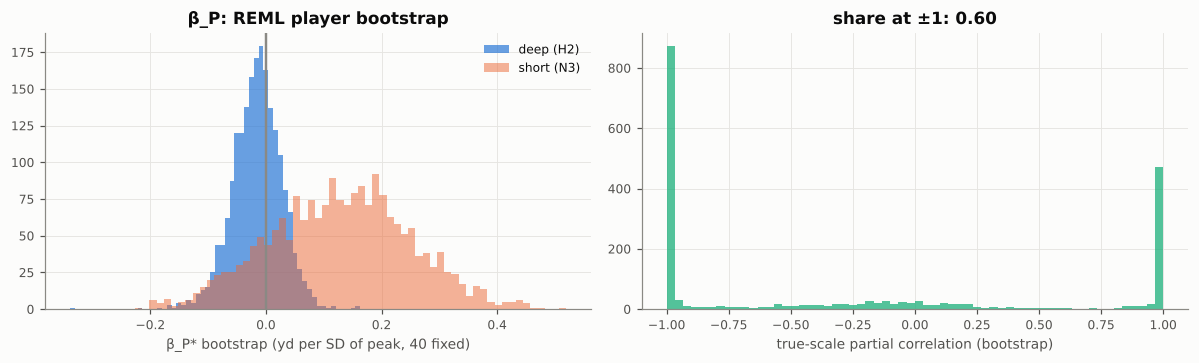

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(BS['deep_beta_P'], bins=60, color=style.SERIES[0], alpha=0.7, label='deep (H2)')
ax[0].hist(BS['short_beta_P'], bins=60, color=style.SERIES[1], alpha=0.5, label='short (N3)')
ax[0].axvline(0, color=style.MUTED); ax[0].set_xlabel('β_P* bootstrap (yd per SD of peak, 40 fixed)'); ax[0].legend(); ax[0].set_title('β_P: REML player bootstrap')
ax[1].hist(BS['deep_partial'], bins=60, color=style.SERIES[2], alpha=0.75)
ax[1].set_xlabel('true-scale partial correlation (bootstrap)'); ax[1].set_title('share at ±1: %.2f' % np.mean(np.abs(BS['deep_partial']) > 0.99))
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/h2_bootstrap.png', dpi=150); plt.show()

## 2. Prediction on held-out players (never held-out plays)

In [4]:
cvf, cve, loo = R['cv_frozen'], R['cv_extended'], R['cv_lopo']
print('Registered criterion engine (frozen h2_cv, 10-fold x 20): R2_CV M1 %.4f, M2 %.4f, ΔR²_CV %.4f; 90%% bootstrap lower bound (B=%d) %.4f' %
      (cvf['r2_m1'], cvf['r2_m2'], cvf['dr2'], R['B_cv'], cvf['lb90']))
rows = []
for m_ in ['M0', 'M1', 'M2', 'M2s', 'M3']:
    rows.append(dict(model=m_, R2_cv=cve[f'R2_{m_}'], RMSE_cv=cve[f'RMSE_{m_}'], spearman_cv=cve[f'spearman_{m_}'], lpd_cv=cve[f'lpd_{m_}'],
                     R2_lopo=loo[f'R2_{m_}'], RMSE_lopo=loo[f'RMSE_{m_}']))
display(pl.DataFrame(rows))
print('extended (stratified by draft class): ΔR² %.4f (SD over repeats %.4f), ΔRMSE %.4f, ΔSpearman %.3f, ΔLPD %.4f' %
      (cve['dR2_CV'], cve['repeat_dR2_sd'], cve['dRMSE_CV'], cve['dSpearman_CV'], cve['dLPD_CV']))
print('season-forward (fit 2023-24, predict 2025 levels):', {k: (round(v, 4) if isinstance(v, float) else v) for k, v in R['season_forward'].items()})

Registered criterion engine (frozen h2_cv, 10-fold x 20): R2_CV M1 -0.0199, M2 -0.0437, ΔR²_CV -0.0238; 90% bootstrap lower bound (B=500) -0.0359


model,R2_cv,RMSE_cv,spearman_cv,lpd_cv,R2_lopo,RMSE_lopo
str,f64,f64,f64,f64,f64,f64
"""M0""",3.3307e-17,0.106916,NaN,0.76772,0.0,0.107087
"""M1""",-0.018061,0.107874,0.094348,0.759496,-0.016827,0.107985
"""M2""",-0.038821,0.108968,0.017284,0.750523,-0.036347,0.109016
"""M2s""",-0.134047,0.113827,-0.095638,0.704209,-0.128834,0.113777
"""M3""",-0.045409,0.109309,-0.021789,0.74538,-0.049039,0.109682


extended (stratified by draft class): ΔR² -0.0208 (SD over repeats 0.0078), ΔRMSE 0.0011, ΔSpearman -0.077, ΔLPD -0.0090
season-forward (fit 2023-24, predict 2025 levels): {'n': 30, 'n_train_players': 40, 'RMSE_M1': 0.1383, 'RMSE_M2': 0.138, 'dRMSE': -0.0003, 'spearman_M1': 0.0922, 'spearman_M2': 0.1012}


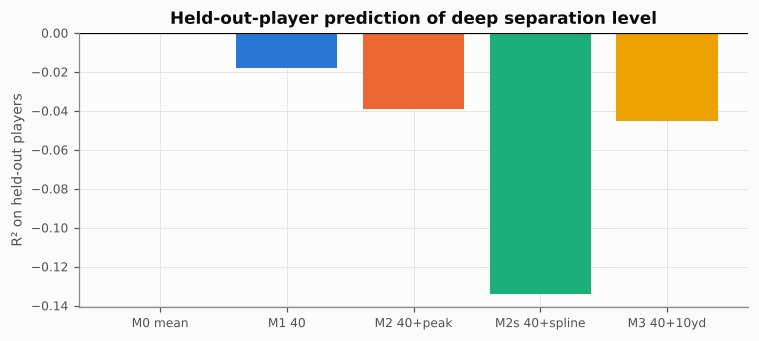

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(5), [cve[f'R2_{m_}'] for m_ in ['M0', 'M1', 'M2', 'M2s', 'M3']], color=[style.MUTED, style.SERIES[0], style.SERIES[1], style.SERIES[2], style.SERIES[3]])
ax.axhline(0, color='k', lw=0.8); ax.set_xticks(range(5), ['M0 mean', 'M1 40', 'M2 40+peak', 'M2s 40+spline', 'M3 40+10yd'])
ax.set_ylabel('R² on held-out players'); ax.set_title('Held-out-player prediction of deep separation level')
fig.tight_layout(); fig.savefig(ROOT / 'reports/figures/h2_cv.png', dpi=150); plt.show()

## 3. Measurement error in the official 40: increment vs precision

In [6]:
display(pl.DataFrame(R['eiv_grid']))
print('registered EIV refit (R_F 0.95, R_x 0.987): β_P %.4f, 95%% bootstrap CI [%.4f, %.4f]' % (R['eiv_registered']['beta_P'], *R['eiv_registered']['ci95']))
print('tipping point as stored by the run (DEFECTIVE helper, = EIV singularity):', R['eiv_tipping_RF'])

rel_F,rel_x,eiv_beta_F,eiv_beta_P
f64,f64,f64,f64
0.85,0.94,0.119008,-0.083242
0.9,0.94,0.073249,-0.041828
0.95,0.94,0.052906,-0.023417
0.99,0.94,0.043289,-0.014712
0.85,0.987,0.090112,-0.054371
0.9,0.987,0.063084,-0.031075
0.95,0.987,0.048529,-0.018528
0.99,0.987,0.040967,-0.01201


registered EIV refit (R_F 0.95, R_x 0.987): β_P -0.0185, 95% bootstrap CI [-0.1287, 0.0787]
tipping point as stored by the run (DEFECTIVE helper, = EIV singularity): {'0.94': 0.7699623294326123, '0.987': 0.7332974566046999}


**Post-run correction (deterministic; no estimate changes).** The stored "tipping points" equal r(F, x)²/R_x. That is the admissibility bound below which the EIV correction is undefined, and where β_P flips sign through infinity. The corrected helper searches only the admissible range.

R_x 0.94: admissible R_F > 0.7700; corrected tipping point: None
R_x 0.987: admissible R_F > 0.7333; corrected tipping point: None


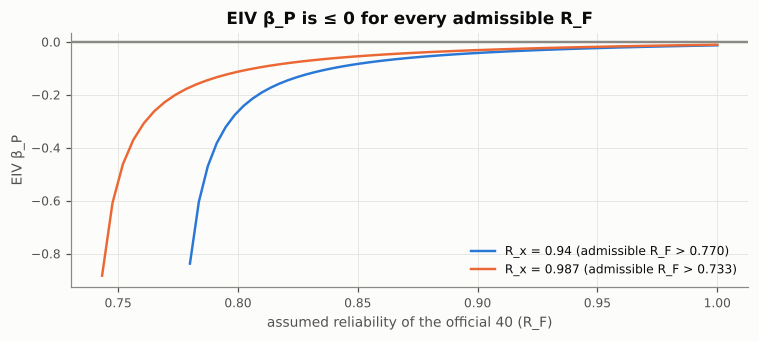

In [7]:
import run_h2_estimation as H
from nfl_bdb.models import confirmatory as cf, h2_extensions as h2
ids, F, x, ten, dc, A = H.load(); D = A['deep']
res = cf.residualise_np(D['W'], D['y']); m, n, sw2 = cf.player_stats(D['pid'], res, len(ids))
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, rx in enumerate((0.94, 0.987)):
    lo = h2.admissible_rel_F(F, x, rx); g = np.linspace(lo + 0.01, 1.0, 60)
    ax.plot(g, [cf.eiv_two_stage(m, n, sw2, F, x, rel_F=f, rel_x=rx)[1] for f in g], color=style.SERIES[k], label=f'R_x = {rx} (admissible R_F > {lo:.3f})')
    print(f'R_x {rx}: admissible R_F > {lo:.4f}; corrected tipping point: {h2.tipping_point(m, n, sw2, F, x, rx)}')
ax.axhline(0, color=style.MUTED); ax.set_xlabel('assumed reliability of the official 40 (R_F)'); ax.set_ylabel('EIV β_P'); ax.legend(fontsize=8)
ax.set_title('EIV β_P is ≤ 0 for every admissible R_F'); fig.tight_layout(); plt.show()

In [8]:
art = pl.DataFrame(R['precision_artefact']).with_columns(pl.col('a').round(3), pl.col('spurious_partial').round(3))
print('validity of the observed 40 for the true deep-separation level (sqrt R² true, F):', round(R['validity_obs'], 3))
art = art.filter(pl.col('rel_x') == 0.987).with_columns(pl.when(pl.col('a') == 0.3).then(pl.lit('a = 0.3')).when(pl.col('a') == 0.6).then(pl.lit('a = 0.6'))
                                                     .otherwise(pl.lit('a = estimated')).alias('validity'))
print('Expected spurious partial (peak | observed 40) if separation depended ONLY on true 40 speed; R_x cancels algebraically.')
print('Observed REML partial for comparison: %.3f (raw β_P %.4f)' % (R['deep']['partial'], R['deep']['beta_P']))
art.pivot(index='rel_F', on='validity', values='spurious_partial').sort('rel_F')

validity of the observed 40 for the true deep-separation level (sqrt R² true, F): 0.273
Expected spurious partial (peak | observed 40) if separation depended ONLY on true 40 speed; R_x cancels algebraically.
Observed REML partial for comparison: -0.081 (raw β_P -0.0200)


rel_F,a = 0.3,a = 0.6,a = estimated
f64,f64,f64,f64
0.8,0.113,0.257,0.115
0.85,0.082,0.19,0.081
0.9,0.053,0.125,0.051
0.95,0.026,0.061,0.024
0.99,0.005,0.012,0.005


## 4. Registered H2 negative control N3: WR short-route separation

In [9]:
s, c = R['short'], R['contrast_N3']
print('short routes: β_P %.4f (Wald SE %.4f), 95%% bootstrap CI [%.4f, %.4f]; β_F %.4f' % (s['beta_P'], s['se_wald'], *rb['short_beta_P']['ci95'], s['beta_F']))
print('contrast β_P(deep) − β_P(short): %.4f, 95%% CI [%.4f, %.4f], 90%% CI [%.4f, %.4f]' % (c['estimate'], *c['ci95'], *c['ci90']))

short routes: β_P 0.1526 (Wald SE 0.0785), 95% bootstrap CI [-0.1090, 0.3653]; β_F -0.0996
contrast β_P(deep) − β_P(short): -0.1726, 95% CI [-0.3917, 0.0875], 90% CI [-0.3537, 0.0517]


## 5. Registered H2 decision criteria (evaluated descriptively, D4)

In [10]:
pl.DataFrame([dict(criterion=k, value=str(v)) for k, v in R['criteria'].items()])

criterion,value
str,str
"""beta_P_positive""","""False"""
"""ci95_excludes_0""","""False"""
"""dR2_CV_ge_0_02""","""False"""
"""dR2_CV_lb90_gt_0""","""False"""
"""season_forward_dRMSE_le_0""","""True"""
"""eiv_beta_P_positive_at_RF_0_95""","""False"""
"""partial_ci90_entirely_below_0_10""","""False"""
"""registered_supported_pattern""","""False"""
"""registered_falsified_pattern""","""False"""


See `research_notes/h2_estimation_results.md` for the interpretation.